In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
customer_features = pd.read_csv(
    "../data/processed/customer_features.csv"
)

restaurant_features = pd.read_csv(
    "../data/processed/restaurant_features.csv"
)

print("Customer dataset:", customer_features.shape)
print("Restaurant dataset:", restaurant_features.shape)

print("\nCustomer features:")
print(customer_features.head())

print("\nRestaurant features:")
print(restaurant_features.head())

Customer dataset: (500, 8)
Restaurant dataset: (100, 7)

Customer features:
   customer_id  total_orders  avg_order_value  total_spending  \
0            1            21       829.851905        17426.89   
1            2            28       732.360357        20506.09   
2            3            24       576.322083        13831.73   
3            4            20       691.538500        13830.77   
4            5            21       620.534762        13031.23   

   ordering_frequency  weekend_orders  late_night_orders  avg_rating_given  
0            3.591236               4                3.0          3.916667  
1            0.622131               7                7.0          4.125000  
2            0.830182               8                6.0          3.916667  
3            0.769659               4                6.0          3.100000  
4            2.166915              12                7.0          4.266667  

Restaurant features:
   restaurant_id  total_orders   revenue  avg_rat

In [3]:
# Keep identifiers separately for later interpretation
customer_ids = customer_features["customer_id"].copy()
restaurant_ids = restaurant_features["restaurant_id"].copy()

# Remove identifiers before clustering
customer_data = customer_features.drop(
    columns=["customer_id"]
).copy()

restaurant_data = restaurant_features.drop(
    columns=["restaurant_id"]
).copy()

print("Customer modelling features:", customer_data.shape)
print("Restaurant modelling features:", restaurant_data.shape)

Customer modelling features: (500, 7)
Restaurant modelling features: (100, 6)


In [4]:
print("Customer missing values:")
print(customer_data.isnull().sum())

print("\nRestaurant missing values:")
print(restaurant_data.isnull().sum())

Customer missing values:
total_orders          0
avg_order_value       0
total_spending        0
ordering_frequency    0
weekend_orders        0
late_night_orders     0
avg_rating_given      0
dtype: int64

Restaurant missing values:
total_orders         0
revenue              0
avg_rating           0
cancellation_rate    0
avg_delivery_time    0
avg_prep_time        0
dtype: int64


In [5]:
customer_data = customer_data.fillna(
    customer_data.median(numeric_only=True)
)

restaurant_data = restaurant_data.fillna(
    restaurant_data.median(numeric_only=True)
)

print("Customer missing values remaining:",
      customer_data.isnull().sum().sum())

print("Restaurant missing values remaining:",
      restaurant_data.isnull().sum().sum())

Customer missing values remaining: 0
Restaurant missing values remaining: 0


In [6]:
customer_scaler = StandardScaler()
restaurant_scaler = StandardScaler()

customer_scaled = customer_scaler.fit_transform(
    customer_data
)

restaurant_scaled = restaurant_scaler.fit_transform(
    restaurant_data
)

# Convert arrays back to DataFrames for easier inspection
customer_scaled_df = pd.DataFrame(
    customer_scaled,
    columns=customer_data.columns
)

restaurant_scaled_df = pd.DataFrame(
    restaurant_scaled,
    columns=restaurant_data.columns
)

print("Customer scaled shape:", customer_scaled_df.shape)
print("Restaurant scaled shape:", restaurant_scaled_df.shape)

Customer scaled shape: (500, 7)
Restaurant scaled shape: (100, 6)


In [7]:
print("Customer feature means:")
print(customer_scaled_df.mean().round(2))

print("\nRestaurant feature means:")
print(restaurant_scaled_df.mean().round(2))

Customer feature means:
total_orders          0.0
avg_order_value       0.0
total_spending        0.0
ordering_frequency    0.0
weekend_orders        0.0
late_night_orders     0.0
avg_rating_given     -0.0
dtype: float64

Restaurant feature means:
total_orders        -0.0
revenue              0.0
avg_rating          -0.0
cancellation_rate    0.0
avg_delivery_time   -0.0
avg_prep_time       -0.0
dtype: float64


In [8]:
print("Customer feature standard deviations:")
print(customer_scaled_df.std(ddof=0).round(2))

print("\nRestaurant feature standard deviations:")
print(restaurant_scaled_df.std(ddof=0).round(2))

Customer feature standard deviations:
total_orders          1.0
avg_order_value       1.0
total_spending        1.0
ordering_frequency    1.0
weekend_orders        1.0
late_night_orders     1.0
avg_rating_given      1.0
dtype: float64

Restaurant feature standard deviations:
total_orders         1.0
revenue              1.0
avg_rating           1.0
cancellation_rate    1.0
avg_delivery_time    1.0
avg_prep_time        1.0
dtype: float64


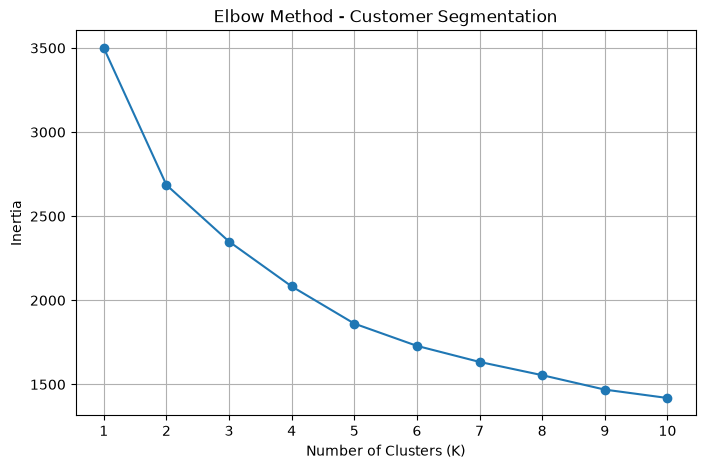

In [10]:
from sklearn.cluster import KMeans

customer_inertia = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(customer_scaled_df)
    customer_inertia.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), customer_inertia, marker="o")
plt.title("Elbow Method - Customer Segmentation")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [9]:
customer_scaled_df.to_csv(
    "../data/processed/customer_scaled.csv",
    index=False
)

restaurant_scaled_df.to_csv(
    "../data/processed/restaurant_scaled.csv",
    index=False
)

print("Scaled datasets saved successfully!")

Scaled datasets saved successfully!


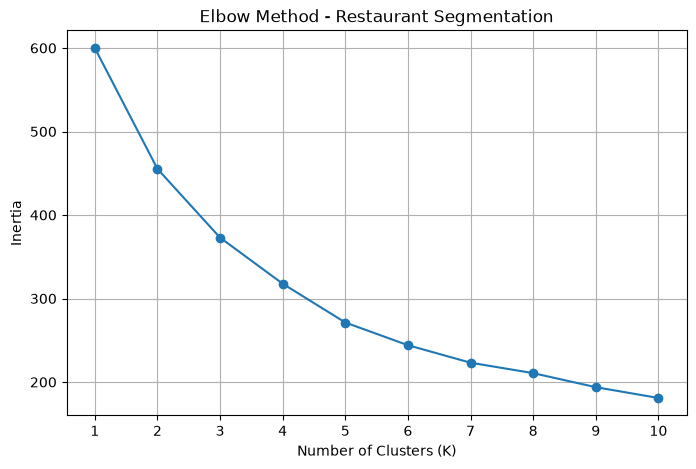

In [11]:
restaurant_inertia = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(restaurant_scaled_df)
    restaurant_inertia.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), restaurant_inertia, marker="o")
plt.title("Elbow Method - Restaurant Segmentation")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [12]:
from sklearn.metrics import silhouette_score

customer_silhouette = {}

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(customer_scaled_df)

    score = silhouette_score(
        customer_scaled_df,
        labels
    )

    customer_silhouette[k] = score

print("Customer Silhouette Scores:")

for k, score in customer_silhouette.items():
    print(f"K={k}: {score:.4f}")

Customer Silhouette Scores:
K=2: 0.2140
K=3: 0.2150
K=4: 0.1772
K=5: 0.1680
K=6: 0.1674
K=7: 0.1558
K=8: 0.1501
K=9: 0.1525
K=10: 0.1483


In [13]:
restaurant_silhouette = {}

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(restaurant_scaled_df)

    score = silhouette_score(
        restaurant_scaled_df,
        labels
    )

    restaurant_silhouette[k] = score

print("Restaurant Silhouette Scores:")

for k, score in restaurant_silhouette.items():
    print(f"K={k}: {score:.4f}")

Restaurant Silhouette Scores:
K=2: 0.2159
K=3: 0.2048
K=4: 0.2186
K=5: 0.2200
K=6: 0.2161
K=7: 0.2055
K=8: 0.2011
K=9: 0.2019
K=10: 0.2125


In [14]:
# Train the final customer K-Means model
customer_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

customer_labels = customer_kmeans.fit_predict(
    customer_scaled_df
)

# Train the final restaurant K-Means model
restaurant_kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

restaurant_labels = restaurant_kmeans.fit_predict(
    restaurant_scaled_df
)

print("Customer cluster counts:")
print(pd.Series(customer_labels).value_counts().sort_index())

print("\nRestaurant cluster counts:")
print(pd.Series(restaurant_labels).value_counts().sort_index())

Customer cluster counts:
0     20
1    260
2    220
Name: count, dtype: int64

Restaurant cluster counts:
0    24
1    20
2    19
3    19
4    18
Name: count, dtype: int64


In [15]:
# Attach cluster labels to the original feature datasets
customer_results = customer_features.copy()
restaurant_results = restaurant_features.copy()

customer_results["cluster"] = customer_labels
restaurant_results["cluster"] = restaurant_labels

print("Customer results:")
print(customer_results.head())

print("\nRestaurant results:")
print(restaurant_results.head())

Customer results:
   customer_id  total_orders  avg_order_value  total_spending  \
0            1            21       829.851905        17426.89   
1            2            28       732.360357        20506.09   
2            3            24       576.322083        13831.73   
3            4            20       691.538500        13830.77   
4            5            21       620.534762        13031.23   

   ordering_frequency  weekend_orders  late_night_orders  avg_rating_given  \
0            3.591236               4                3.0          3.916667   
1            0.622131               7                7.0          4.125000   
2            0.830182               8                6.0          3.916667   
3            0.769659               4                6.0          3.100000   
4            2.166915              12                7.0          4.266667   

   cluster  
0        1  
1        2  
2        2  
3        1  
4        2  

Restaurant results:
   restaurant_id  total

In [16]:
customer_profile = customer_results.groupby("cluster").agg(
    customer_count=("customer_id", "count"),
    avg_total_orders=("total_orders", "mean"),
    avg_order_value=("avg_order_value", "mean"),
    avg_total_spending=("total_spending", "mean"),
    avg_ordering_frequency=("ordering_frequency", "mean"),
    avg_weekend_orders=("weekend_orders", "mean"),
    avg_late_night_orders=("late_night_orders", "mean"),
    avg_rating_given=("avg_rating_given", "mean")
).round(2)

print(customer_profile)

         customer_count  avg_total_orders  avg_order_value  \
cluster                                                      
0                    20             22.90           788.24   
1                   260             17.09           742.78   
2                   220             23.17           774.05   

         avg_total_spending  avg_ordering_frequency  avg_weekend_orders  \
cluster                                                                   
0                  18052.58                   17.05                7.80   
1                  12618.33                    1.14                4.58   
2                  17878.37                    1.60                7.04   

         avg_late_night_orders  avg_rating_given  
cluster                                           
0                         6.45              3.44  
1                         4.63              3.71  
2                         7.14              3.76  


In [17]:
restaurant_profile = restaurant_results.groupby("cluster").agg(
    restaurant_count=("restaurant_id", "count"),
    avg_total_orders=("total_orders", "mean"),
    avg_revenue=("revenue", "mean"),
    avg_rating=("avg_rating", "mean"),
    avg_prep_time=("avg_prep_time", "mean"),
    avg_cancellation_rate=("cancellation_rate", "mean"),
    avg_delivery_time=("avg_delivery_time", "mean")
).round(2)

print(restaurant_profile)

         restaurant_count  avg_total_orders  avg_revenue  avg_rating  \
cluster                                                                
0                      24             93.54     69106.92        3.82   
1                      20             94.20     72596.58        3.73   
2                      19            104.21     78760.67        3.83   
3                      19            112.47     86523.59        3.72   
4                      18             97.44     73564.47        3.48   

         avg_prep_time  avg_cancellation_rate  avg_delivery_time  
cluster                                                           
0                28.33                   9.09              63.17  
1                15.10                   6.37              49.57  
2                35.37                   5.83              69.58  
3                20.63                   7.00              54.54  
4                30.17                   6.03              64.95  


In [18]:
customer_cluster_names = {
    0: "Frequent High-Value Customers",
    1: "Low-Frequency Customers",
    2: "Engaged Regular Customers"
}

restaurant_cluster_names = {
    0: "Lower-Revenue, High-Cancellation Restaurants",
    1: "Fast and Reliable Restaurants",
    2: "High-Revenue, Slow-Service Restaurants",
    3: "High-Volume, High-Revenue Restaurants",
    4: "Restaurants Needing Service Improvements"
}

customer_results["segment"] = customer_results["cluster"].map(customer_cluster_names)
restaurant_results["segment"] = restaurant_results["cluster"].map(restaurant_cluster_names)

print(customer_results[["customer_id", "cluster", "segment"]].head())
print()
print(restaurant_results[["restaurant_id", "cluster", "segment"]].head())

   customer_id  cluster                    segment
0            1        1    Low-Frequency Customers
1            2        2  Engaged Regular Customers
2            3        2  Engaged Regular Customers
3            4        1    Low-Frequency Customers
4            5        2  Engaged Regular Customers

   restaurant_id  cluster                                       segment
0              1        4      Restaurants Needing Service Improvements
1              2        0  Lower-Revenue, High-Cancellation Restaurants
2              3        0  Lower-Revenue, High-Cancellation Restaurants
3              4        4      Restaurants Needing Service Improvements
4              5        4      Restaurants Needing Service Improvements


In [19]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

In [20]:
customer_dbscan = DBSCAN(eps=1.5, min_samples=5)

customer_dbscan_labels = customer_dbscan.fit_predict(customer_scaled_df)

customer_results["dbscan_cluster"] = customer_dbscan_labels

print("Customer DBSCAN cluster counts:")
print(customer_results["dbscan_cluster"].value_counts().sort_index())

Customer DBSCAN cluster counts:
dbscan_cluster
-1     50
 0    450
Name: count, dtype: int64


In [21]:
restaurant_dbscan = DBSCAN(eps=1.5, min_samples=5)

restaurant_dbscan_labels = restaurant_dbscan.fit_predict(restaurant_scaled_df)

restaurant_results["dbscan_cluster"] = restaurant_dbscan_labels

print("Restaurant DBSCAN cluster counts:")
print(restaurant_results["dbscan_cluster"].value_counts().sort_index())

Restaurant DBSCAN cluster counts:
dbscan_cluster
-1    27
 0    73
Name: count, dtype: int64


In [22]:
from sklearn.decomposition import PCA

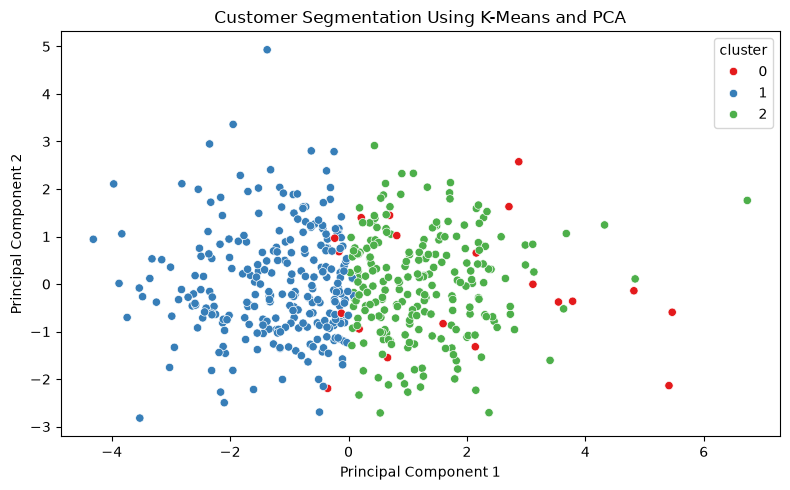

Variance explained by the two components: 55.62 %


In [23]:
customer_pca = PCA(n_components=2)

customer_pca_data = customer_pca.fit_transform(customer_scaled_df)

customer_pca_df = pd.DataFrame(
    customer_pca_data,
    columns=["PC1", "PC2"]
)

customer_pca_df["cluster"] = customer_labels

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=customer_pca_df,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette="Set1"
)

plt.title("Customer Segmentation Using K-Means and PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.show()

print(
    "Variance explained by the two components:",
    round(customer_pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

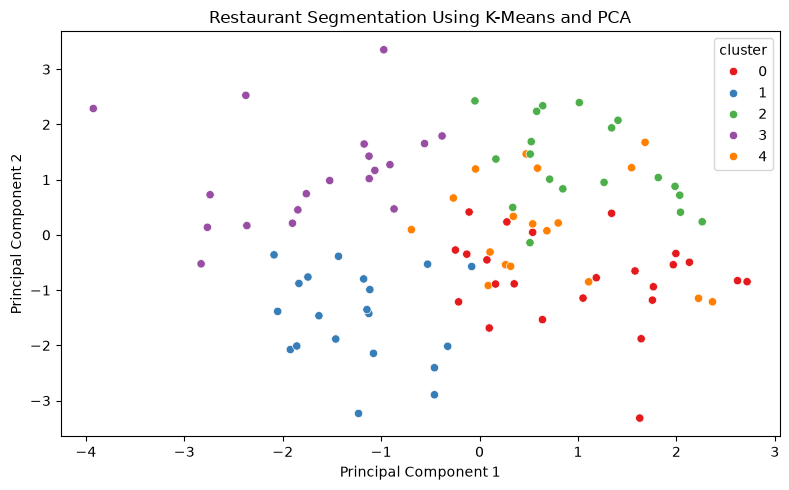

Variance explained by the two components: 64.82 %


In [24]:
restaurant_pca = PCA(n_components=2)

restaurant_pca_data = restaurant_pca.fit_transform(restaurant_scaled_df)

restaurant_pca_df = pd.DataFrame(
    restaurant_pca_data,
    columns=["PC1", "PC2"]
)

restaurant_pca_df["cluster"] = restaurant_labels

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=restaurant_pca_df,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette="Set1"
)

plt.title("Restaurant Segmentation Using K-Means and PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.show()

print(
    "Variance explained by the two components:",
    round(restaurant_pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

In [25]:
from sklearn.metrics import silhouette_score

customer_silhouette = silhouette_score(
    customer_scaled_df,
    customer_labels
)

restaurant_silhouette = silhouette_score(
    restaurant_scaled_df,
    restaurant_labels
)

print("Customer K-Means Silhouette Score:", round(customer_silhouette, 4))
print("Restaurant K-Means Silhouette Score:", round(restaurant_silhouette, 4))

Customer K-Means Silhouette Score: 0.215
Restaurant K-Means Silhouette Score: 0.22


In [26]:
# Customer DBSCAN evaluation
customer_valid_labels = customer_dbscan_labels[
    customer_dbscan_labels != -1
]

customer_unique_clusters = set(customer_valid_labels)

if len(customer_unique_clusters) >= 2:
    customer_dbscan_silhouette = silhouette_score(
        customer_scaled_df[customer_dbscan_labels != -1],
        customer_valid_labels
    )
    print("Customer DBSCAN Silhouette Score:",
          round(customer_dbscan_silhouette, 4))
else:
    print("Customer DBSCAN Silhouette Score: Not applicable")
    print("DBSCAN found fewer than two non-noise clusters.")


# Restaurant DBSCAN evaluation
restaurant_valid_labels = restaurant_dbscan_labels[
    restaurant_dbscan_labels != -1
]

restaurant_unique_clusters = set(restaurant_valid_labels)

if len(restaurant_unique_clusters) >= 2:
    restaurant_dbscan_silhouette = silhouette_score(
        restaurant_scaled_df[restaurant_dbscan_labels != -1],
        restaurant_valid_labels
    )
    print("Restaurant DBSCAN Silhouette Score:",
          round(restaurant_dbscan_silhouette, 4))
else:
    print("Restaurant DBSCAN Silhouette Score: Not applicable")
    print("DBSCAN found fewer than two non-noise clusters.")

Customer DBSCAN Silhouette Score: Not applicable
DBSCAN found fewer than two non-noise clusters.
Restaurant DBSCAN Silhouette Score: Not applicable
DBSCAN found fewer than two non-noise clusters.


In [27]:
# Save final customer segmentation results
customer_results.to_csv(
    "../data/processed/customer_segmentation_results.csv",
    index=False
)

# Save final restaurant segmentation results
restaurant_results.to_csv(
    "../data/processed/restaurant_segmentation_results.csv",
    index=False
)

print("Customer segmentation results saved.")
print("Restaurant segmentation results saved.")

Customer segmentation results saved.
Restaurant segmentation results saved.


In [28]:
print("Customer dataset shape:", customer_results.shape)
print("Restaurant dataset shape:", restaurant_results.shape)

print("\nCustomer columns:")
print(customer_results.columns.tolist())

print("\nRestaurant columns:")
print(restaurant_results.columns.tolist())

Customer dataset shape: (500, 11)
Restaurant dataset shape: (100, 10)

Customer columns:
['customer_id', 'total_orders', 'avg_order_value', 'total_spending', 'ordering_frequency', 'weekend_orders', 'late_night_orders', 'avg_rating_given', 'cluster', 'segment', 'dbscan_cluster']

Restaurant columns:
['restaurant_id', 'total_orders', 'revenue', 'avg_rating', 'cancellation_rate', 'avg_delivery_time', 'avg_prep_time', 'cluster', 'segment', 'dbscan_cluster']
